# Phase 04 — Canonical Manifest, Split Governance, & Patient Grouping Integrity

**Reviewer-Facing Reproducibility Notebook**  
**Phase ID:** `phase_04_manifest_splits`  
**Current Milestone:** Part 1A — Split Integrity, Hash Governance, Patient Grouping, Semantic Schema, and Reviewer Visualization  
**Hardware Profile:** NVIDIA GeForce RTX 3060 Ti (8GB VRAM)  
**Execution Environment:** `jup-venv` (`D:\Softfors\jup\.venv\Scripts\python.exe`)


## 1. Scientific Question
What is the exact canonical paired-data manifest, how are the 8,441 multi-domain medical cases partitioned into TRAIN, VAL, and TEST splits, and can those splits be deterministically reproduced and cryptographically verified without opening locked TEST image content?

This phase establishes the immutable population partition and patient grouping boundaries governing all downstream machine learning training and evaluation.


## 2. Relation to Phase 03 Multi-Domain Dataset Discovery
In **Phase 03**, we discovered the raw multi-domain dataset inventory and established exact paired sample counts:
- **ISIC 2018**: 3,694 paired dermoscopy cases
- **BUSI**: 927 paired breast ultrasound cases
- **Kvasir-SEG**: 1,000 paired polyp endoscopy cases
- **KUB-Stone**: 2,820 paired kidney-ureter-bladder abdominal radiograph cases
- **Authoritative Population**: 8,441 paired cases (historical 8,159 count documented as provenance unresolved)

Phase 04 builds directly upon this population by auditing the formal split allocation (`TRAIN`, `VAL`, `TEST`), verifying strict patient-level separation in KUB, and confirming that no split overlap or cross-contamination exists.


## 3. Critical Governance Distinction: Metadata Reads vs. Content Access

Under the strict project reproducibility protocol:
- **TEST Manifest Metadata Reads (ALLOWED):** Reading tabular metadata (sample ID, split name, dataset name, patient ID, manifest row counts, and cryptographic hashes) from the frozen canonical manifest files is permitted to verify partitioning integrity.
- **TEST Image Content Reads (STRICTLY 0):** No TEST images are opened, decoded, or read into memory.
- **TEST Mask Content Reads (STRICTLY 0):** No TEST ground-truth segmentation masks are opened, decoded, or read into memory.
- **TEST Visualizations (STRICTLY 0):** No medical imagery from the TEST split is displayed.
- **TEST Metrics / Inference (STRICTLY NONE):** No model inference, optimizer steps, or quantitative test evaluations occur.


## 4. Canonical Manifest Artifacts & Cryptographic Verification
We audit the four canonical manifest files in `manifests/` and verify their SHA-256 binary digests against accepted reference values.


In [1]:
import sys
import hashlib
from pathlib import Path
import pandas as pd

# Add project root to sys.path
PROJECT_ROOT = Path("D:/Softfors/jup")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

manifest_files = {
    "all_paired": PROJECT_ROOT / "manifests/all_paired.csv",
    "train": PROJECT_ROOT / "manifests/train.csv",
    "val": PROJECT_ROOT / "manifests/val.csv",
    "test": PROJECT_ROOT / "manifests/test.csv"
}

accepted_hashes = {
    "all_paired": "66350d465209e4bf0948a16f0da213abb9f8f87c0b222ead7632d2350463f7cc",
    "train": "d67b549a6cc80b579dfaf4976b9b51630f6d703d8c6bfb33188355cfa6056bc3",
    "val": "46079b594ed9535c2de953bb976684b8b0bab30c27c6e6e4f2b9f9314b4cc5f4",
    "test": "9361eba61c91c034a9aa4988a4df229bba591a5cbd553c98689ac7915da29727"
}

hash_records = []
for name, p in manifest_files.items():
    h = hashlib.sha256(p.read_bytes()).hexdigest()
    exp = accepted_hashes[name]
    hash_records.append({
        "Manifest File": p.name,
        "Row Count": len(pd.read_csv(p)),
        "Computed SHA-256": h,
        "Accepted SHA-256": exp,
        "Status": "PASS (Exact Match)" if h == exp else "FAIL"
    })

pd.set_option('display.max_colwidth', None)
df_hash_audit = pd.DataFrame(hash_records)
df_hash_audit


,Manifest File,Row Count,Computed SHA-256,Accepted SHA-256,Status
0,all_paired.csv,8441,66350d465209e4bf0948a16f0da213abb9f8f87c0b222ead7632d2350463f7cc,66350d465209e4bf0948a16f0da213abb9f8f87c0b222ead7632d2350463f7cc,PASS (Exact Match)
1,train.csv,5913,d67b549a6cc80b579dfaf4976b9b51630f6d703d8c6bfb33188355cfa6056bc3,d67b549a6cc80b579dfaf4976b9b51630f6d703d8c6bfb33188355cfa6056bc3,PASS (Exact Match)
2,val.csv,845,46079b594ed9535c2de953bb976684b8b0bab30c27c6e6e4f2b9f9314b4cc5f4,46079b594ed9535c2de953bb976684b8b0bab30c27c6e6e4f2b9f9314b4cc5f4,PASS (Exact Match)
3,test.csv,1683,9361eba61c91c034a9aa4988a4df229bba591a5cbd553c98689ac7915da29727,9361eba61c91c034a9aa4988a4df229bba591a5cbd553c98689ac7915da29727,PASS (Exact Match)


## 5. Canonical Manifest Schema Audit
We inspect the actual column schema of `manifests/all_paired.csv` to document the exact data types, missing value counts, and governance role of every column.


In [2]:
df_all = pd.read_csv(manifest_files["all_paired"])

schema_info = [
    {"Column": "dataset", "Meaning": "Name of medical dataset cohort", "Dtype": str(df_all['dataset'].dtype), "Required": True, "Missing Count": int(df_all['dataset'].isna().sum()), "Governance Role": "Domain stratification"},
    {"Column": "task_id", "Meaning": "Internal task/domain integer identifier", "Dtype": str(df_all['task_id'].dtype), "Required": True, "Missing Count": int(df_all['task_id'].isna().sum()), "Governance Role": "Multitask indexing"},
    {"Column": "image_path", "Meaning": "Relative path to raw medical image file", "Dtype": str(df_all['image_path'].dtype), "Required": True, "Missing Count": int(df_all['image_path'].isna().sum()), "Governance Role": "Input asset reference"},
    {"Column": "mask_path", "Meaning": "Relative path to ground truth segmentation mask", "Dtype": str(df_all['mask_path'].dtype), "Required": True, "Missing Count": int(df_all['mask_path'].isna().sum()), "Governance Role": "Target asset reference"},
    {"Column": "patient_id", "Meaning": "Patient identifier (available for KUB; NOT_AVAILABLE for others)", "Dtype": str(df_all['patient_id'].dtype), "Required": True, "Missing Count": int(df_all['patient_id'].isna().sum()), "Governance Role": "Patient grouping protection"},
    {"Column": "case_id", "Meaning": "Source dataset original case identifier", "Dtype": str(df_all['case_id'].dtype), "Required": True, "Missing Count": int(df_all['case_id'].isna().sum()), "Governance Role": "Source provenance"},
    {"Column": "category", "Meaning": "Subclass/clinical metadata (e.g. stone anatomy in KUB)", "Dtype": str(df_all['category'].dtype), "Required": True, "Missing Count": int(df_all['category'].isna().sum()), "Governance Role": "Stratified auditing (not pixel class)"},
    {"Column": "sample_id", "Meaning": "Unique 32-hex hash identifying the paired case", "Dtype": str(df_all['sample_id'].dtype), "Required": True, "Missing Count": int(df_all['sample_id'].isna().sum()), "Governance Role": "Primary key & disjointness checking"},
    {"Column": "split", "Meaning": "Split assignment: TRAIN, VAL, or TEST", "Dtype": str(df_all['split'].dtype), "Required": True, "Missing Count": int(df_all['split'].isna().sum()), "Governance Role": "Execution boundary governance"}
]

df_schema = pd.DataFrame(schema_info)
df_schema


,Column,Meaning,Dtype,Required,Missing Count,Governance Role
0,dataset,Name of medical dataset cohort,str,True,0,Domain stratification
1,task_id,Internal task/domain integer identifier,int64,True,0,Multitask indexing
2,image_path,Relative path to raw medical image file,str,True,0,Input asset reference
3,mask_path,Relative path to ground truth segmentation mask,str,True,0,Target asset reference
4,patient_id,Patient identifier (available for KUB; NOT_AVAILABLE for others),str,True,0,Patient grouping protection
5,case_id,Source dataset original case identifier,str,True,0,Source provenance
6,category,Subclass/clinical metadata (e.g. stone anatomy in KUB),str,True,0,Stratified auditing (not pixel class)
7,sample_id,Unique 32-hex hash identifying the paired case,str,True,0,Primary key & disjointness checking
8,split,"Split assignment: TRAIN, VAL, or TEST",str,True,0,Execution boundary governance


## 6. Binary Semantic Segmentation Label Schema
Carrying forward the semantic clarification established in Phase 03, all four medical datasets are formulated as **binary semantic segmentation** tasks. Diagnostic pathology labels (ISIC, BUSI) and anatomical location categories (KUB) represent **case-level clinical metadata**, NOT multiclass pixel targets.


In [3]:
label_schema = [
    {"Dataset": "ISIC 2018", "Pixel-Level Target": "Skin Lesion", "Pixel Classes": "Class 0: Background, Class 1: Lesion", "Subclass Metadata": "Diagnostic classification (NOT_AVAILABLE in manifest)", "Metadata Level": "Case", "Used to Define Split": "No", "Used as Pixel Class": "No (Binary Only)"},
    {"Dataset": "BUSI", "Pixel-Level Target": "Breast Lesion", "Pixel Classes": "Class 0: Background, Class 1: Lesion", "Subclass Metadata": "Tumor histology (NOT_AVAILABLE in manifest)", "Metadata Level": "Case", "Used to Define Split": "No", "Used as Pixel Class": "No (Binary Only)"},
    {"Dataset": "Kvasir-SEG", "Pixel-Level Target": "Colorectal Polyp", "Pixel Classes": "Class 0: Background, Class 1: Polyp", "Subclass Metadata": "None (NOT_AVAILABLE in manifest)", "Metadata Level": "Case", "Used to Define Split": "No", "Used as Pixel Class": "No (Binary Only)"},
    {"Dataset": "KUB-Stone", "Pixel-Level Target": "Urinary Calculus (Stone)", "Pixel Classes": "Class 0: Background, Class 1: Stone", "Subclass Metadata": "Kidney, Bladder, Ureteric", "Metadata Level": "Case", "Used to Define Split": "No (Grouped by Patient)", "Used as Pixel Class": "No (Binary Only)"}
]

df_label_schema = pd.DataFrame(label_schema)
df_label_schema


,Dataset,Pixel-Level Target,Pixel Classes,Subclass Metadata,Metadata Level,Used to Define Split,Used as Pixel Class
0,ISIC 2018,Skin Lesion,"Class 0: Background, Class 1: Lesion",Diagnostic classification (NOT_AVAILABLE in manifest),Case,No,No (Binary Only)
1,BUSI,Breast Lesion,"Class 0: Background, Class 1: Lesion",Tumor histology (NOT_AVAILABLE in manifest),Case,No,No (Binary Only)
2,Kvasir-SEG,Colorectal Polyp,"Class 0: Background, Class 1: Polyp",None (NOT_AVAILABLE in manifest),Case,No,No (Binary Only)
3,KUB-Stone,Urinary Calculus (Stone),"Class 0: Background, Class 1: Stone","Kidney, Bladder, Ureteric",Case,No (Grouped by Patient),No (Binary Only)


## 7. Overall Population Partitioning & Split Counts
We calculate the split population counts across all 8,441 paired cases and verify against reference project numbers.


In [4]:
train_count = (df_all['split'] == 'TRAIN').sum()
val_count = (df_all['split'] == 'VAL').sum()
test_count = (df_all['split'] == 'TEST').sum()
total_count = len(df_all)

print(f"Total Canonical Population: {total_count:,} (Expected: 8,441)")
print(f"  - TRAIN Allocation     : {train_count:,} ({train_count/total_count*100:.2f}%) [Expected: 5,913]")
print(f"  - VAL Allocation       : {val_count:,} ({val_count/total_count*100:.2f}%) [Expected: 845]")
print(f"  - TEST Allocation      : {test_count:,} ({test_count/total_count*100:.2f}%) [Expected: 1,683]")

assert train_count + val_count + test_count == total_count == 8441, "Split counts do not sum to 8,441!"
print("\nAudit Result: PASS (Population counts match exact reference values).")


Total Canonical Population: 8,441 (Expected: 8,441)
  - TRAIN Allocation     : 5,913 (70.05%) [Expected: 5,913]
  - VAL Allocation       : 845 (10.01%) [Expected: 845]
  - TEST Allocation      : 1,683 (19.94%) [Expected: 1,683]

Audit Result: PASS (Population counts match exact reference values).


## 8. Dataset-Wise Split Breakdown
We evaluate the split distributions within each individual dataset cohort.


In [5]:
ct_splits = pd.crosstab(df_all['dataset'], df_all['split'])[['TRAIN', 'VAL', 'TEST']].reindex(['ISIC', 'BUSI', 'KVASIR', 'KUB'])
ct_splits['Total'] = ct_splits.sum(axis=1)

# Append Total Row
all_row = pd.Series({
    'TRAIN': ct_splits['TRAIN'].sum(),
    'VAL': ct_splits['VAL'].sum(),
    'TEST': ct_splits['TEST'].sum(),
    'Total': ct_splits['Total'].sum()
}, name='Authoritative Total')
ct_display = pd.concat([ct_splits, all_row.to_frame().T])
ct_display


,TRAIN,VAL,TEST,Total
ISIC,2581,378,735,3694
BUSI,656,97,174,927
KVASIR,697,87,216,1000
KUB,1979,283,558,2820
Authoritative Total,5913,845,1683,8441


## 9. Split Proportions & Visual Distribution
We visualize the dataset split counts and normalized proportions using publication-ready figures.


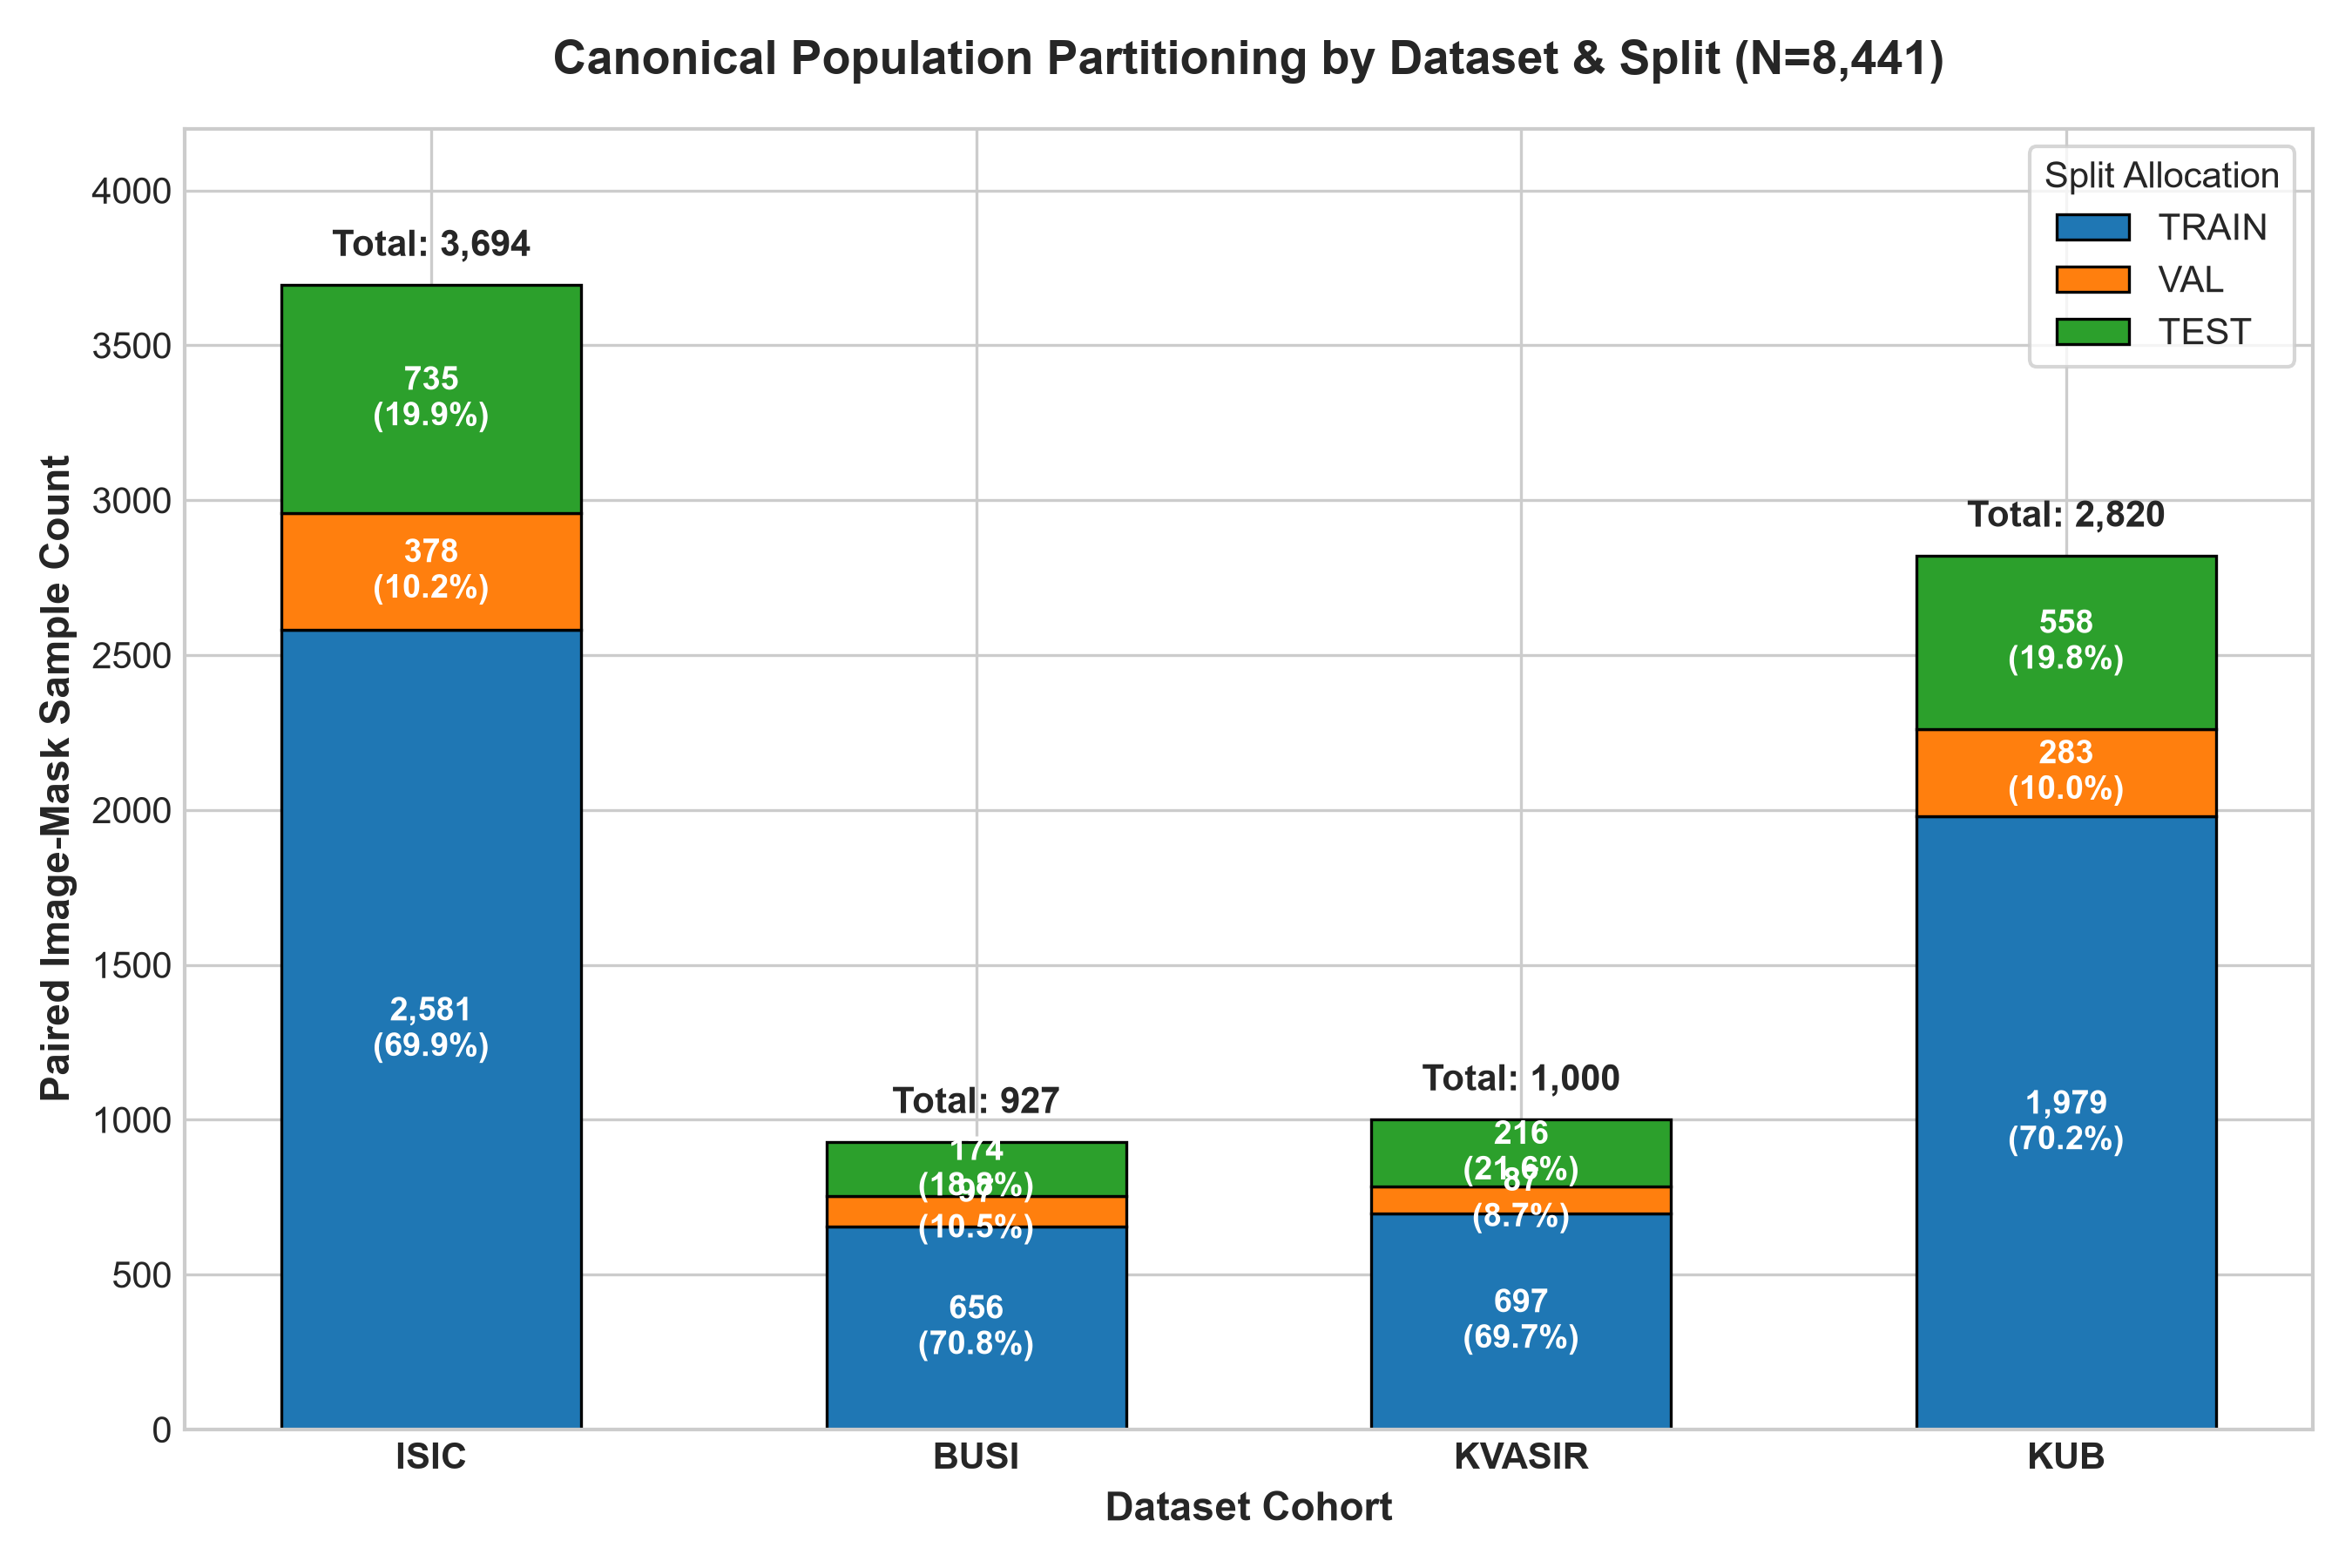

In [6]:
from IPython.display import Image, display

# Display Figure 1: Dataset Split Counts (Stacked Bar Chart)
fig1_path = PROJECT_ROOT / "reports/figures/phase04_manifest_splits/aggregate/phase04_dataset_split_counts.png"
display(Image(filename=str(fig1_path)))


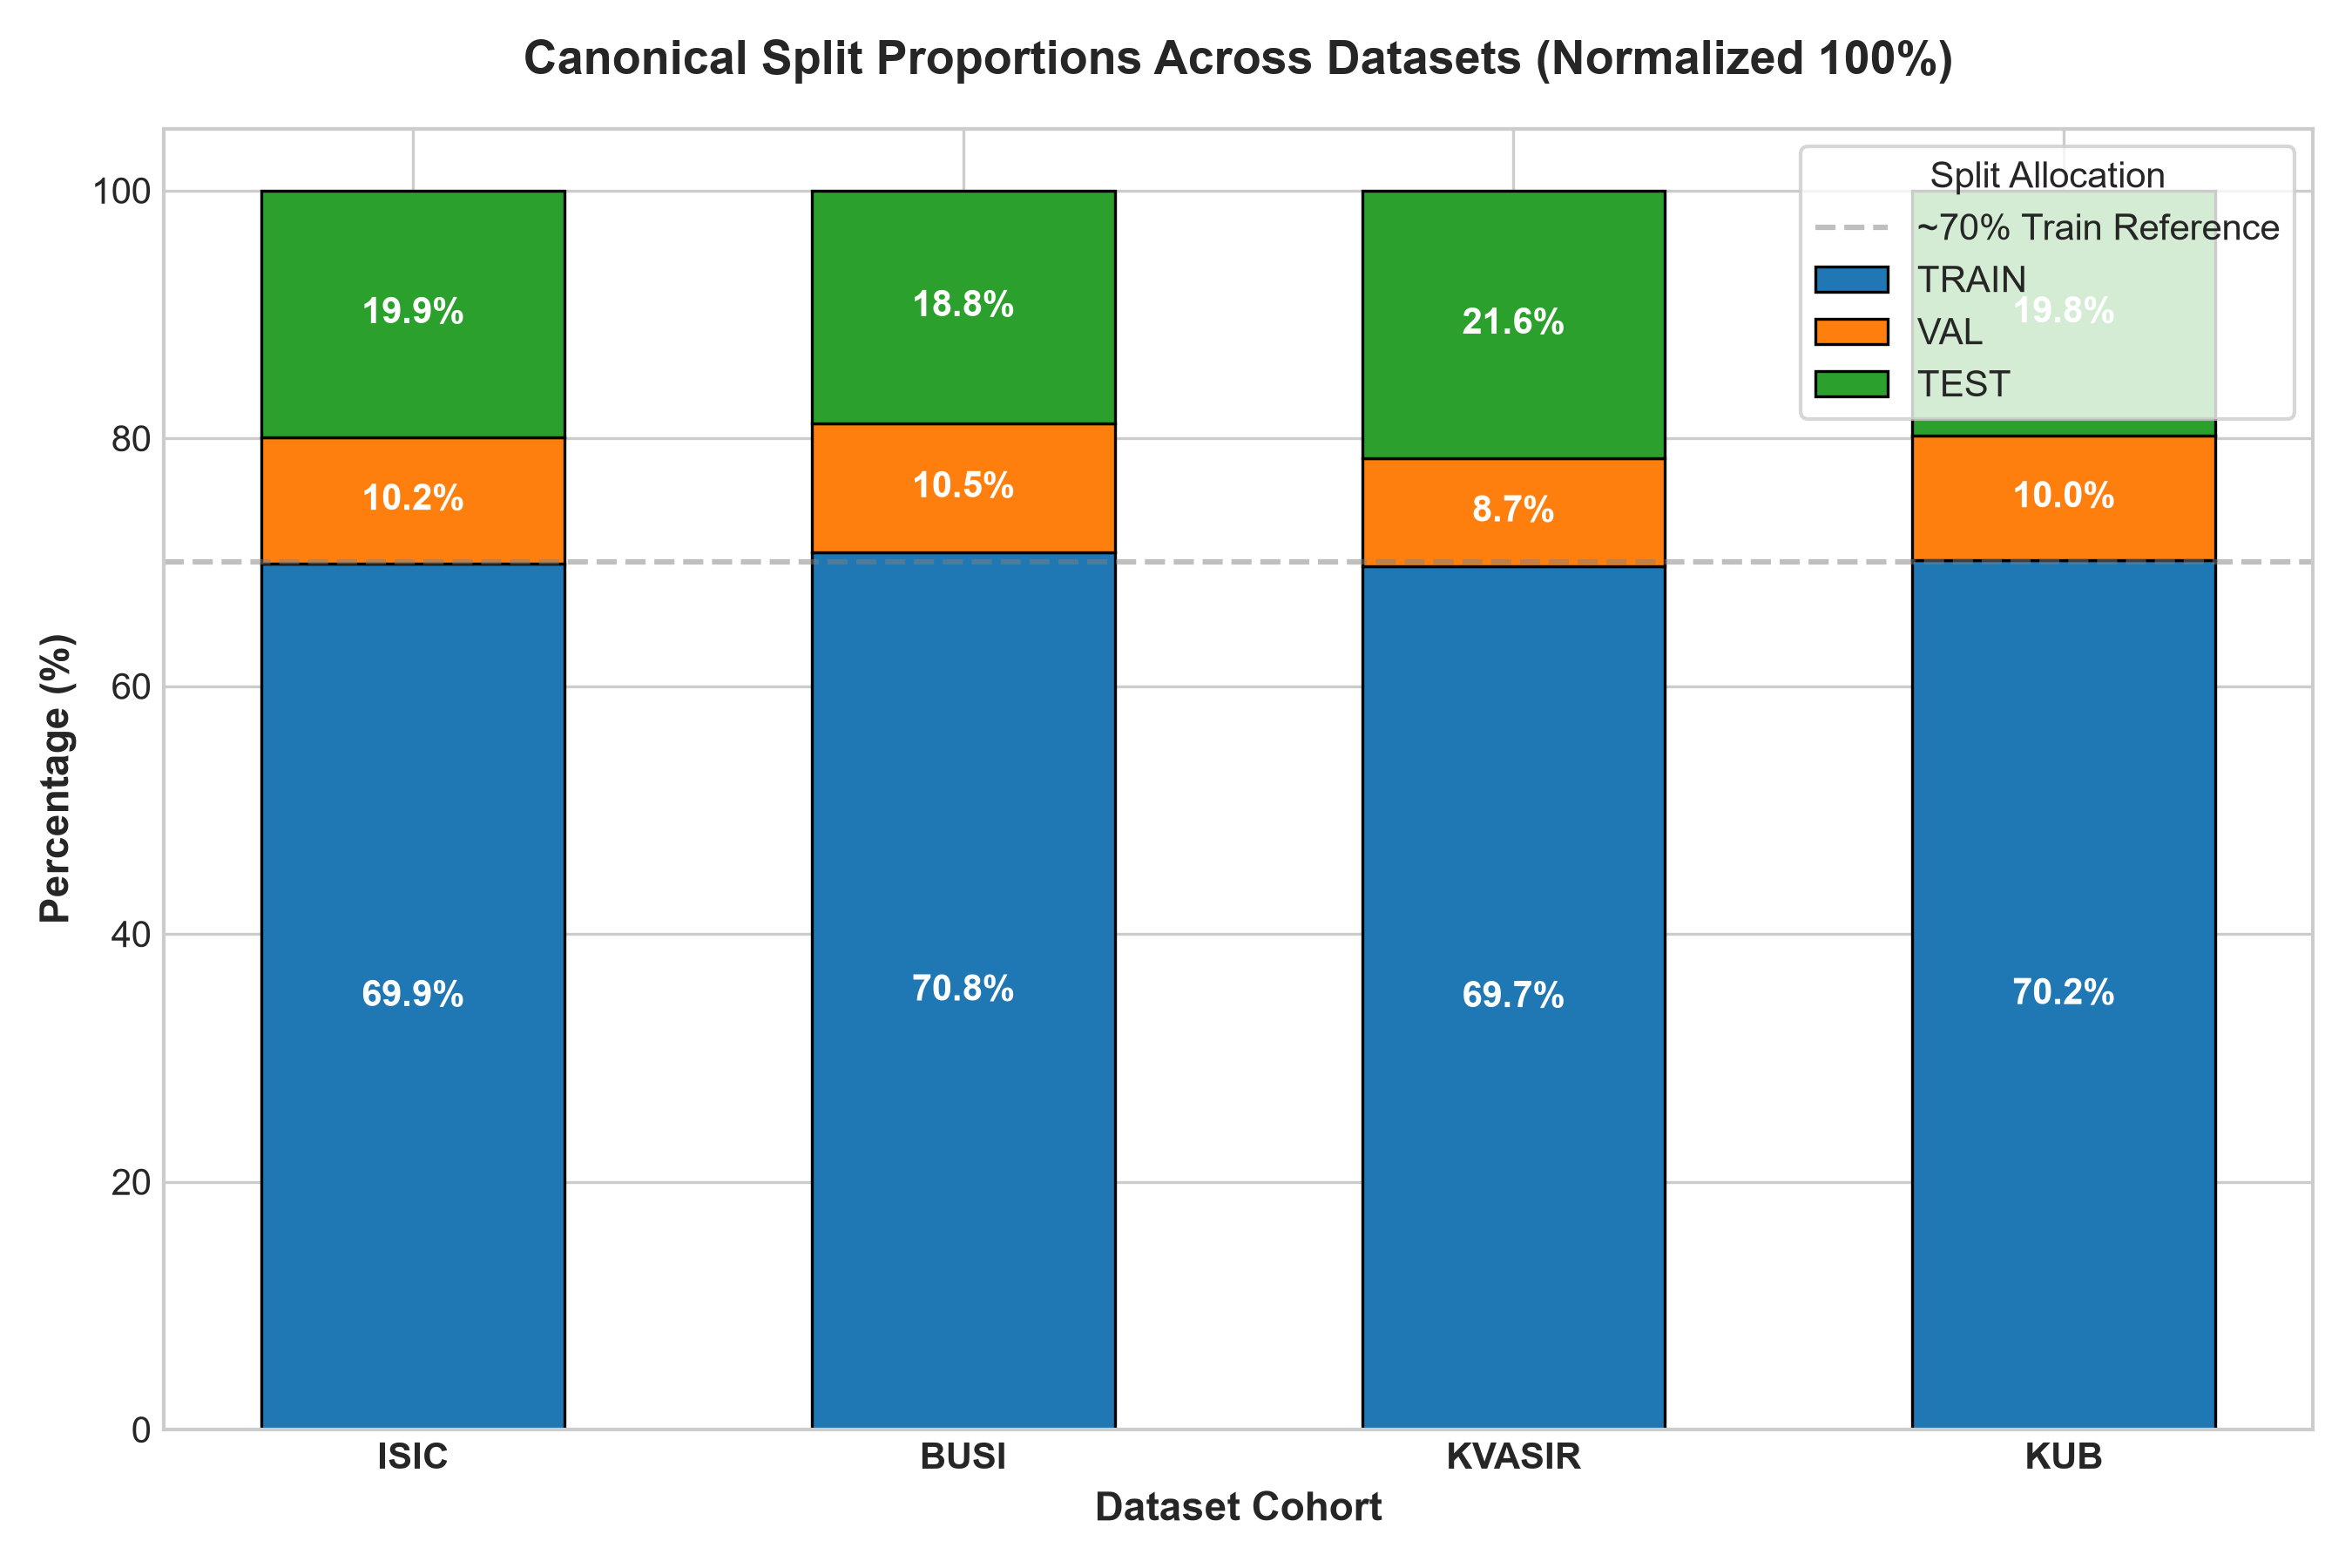

In [7]:
# Display Figure 2: Normalized 100% Stacked Bar Chart
fig2_path = PROJECT_ROOT / "reports/figures/phase04_manifest_splits/aggregate/phase04_dataset_split_proportions.png"
display(Image(filename=str(fig2_path)))


## 10. Unique Sample Membership & Split Disjointness
To verify that no sample ID appears in multiple splits, we perform rigorous set intersection audits across all split pairs.


In [8]:
train_ids = set(df_all[df_all['split'] == 'TRAIN']['sample_id'])
val_ids = set(df_all[df_all['split'] == 'VAL']['sample_id'])
test_ids = set(df_all[df_all['split'] == 'TEST']['sample_id'])

ov_tv = len(train_ids & val_ids)
ov_tt = len(train_ids & test_ids)
ov_vt = len(val_ids & test_ids)
unique_ids = df_all['sample_id'].nunique()

print(f"Total Unique Sample IDs: {unique_ids:,} / {len(df_all):,}")
print(f"  - TRAIN & VAL Overlap : {ov_tv} (Expected: 0)")
print(f"  - TRAIN & TEST Overlap: {ov_tt} (Expected: 0)")
print(f"  - VAL & TEST Overlap  : {ov_vt} (Expected: 0)")

assert ov_tv == 0 and ov_tt == 0 and ov_vt == 0 and unique_ids == 8441, "Split overlap detected!"
print("\nAudit Result: PASS (All splits are strictly pairwise disjoint).")


Total Unique Sample IDs: 8,441 / 8,441
  - TRAIN & VAL Overlap : 0 (Expected: 0)
  - TRAIN & TEST Overlap: 0 (Expected: 0)
  - VAL & TEST Overlap  : 0 (Expected: 0)

Audit Result: PASS (All splits are strictly pairwise disjoint).


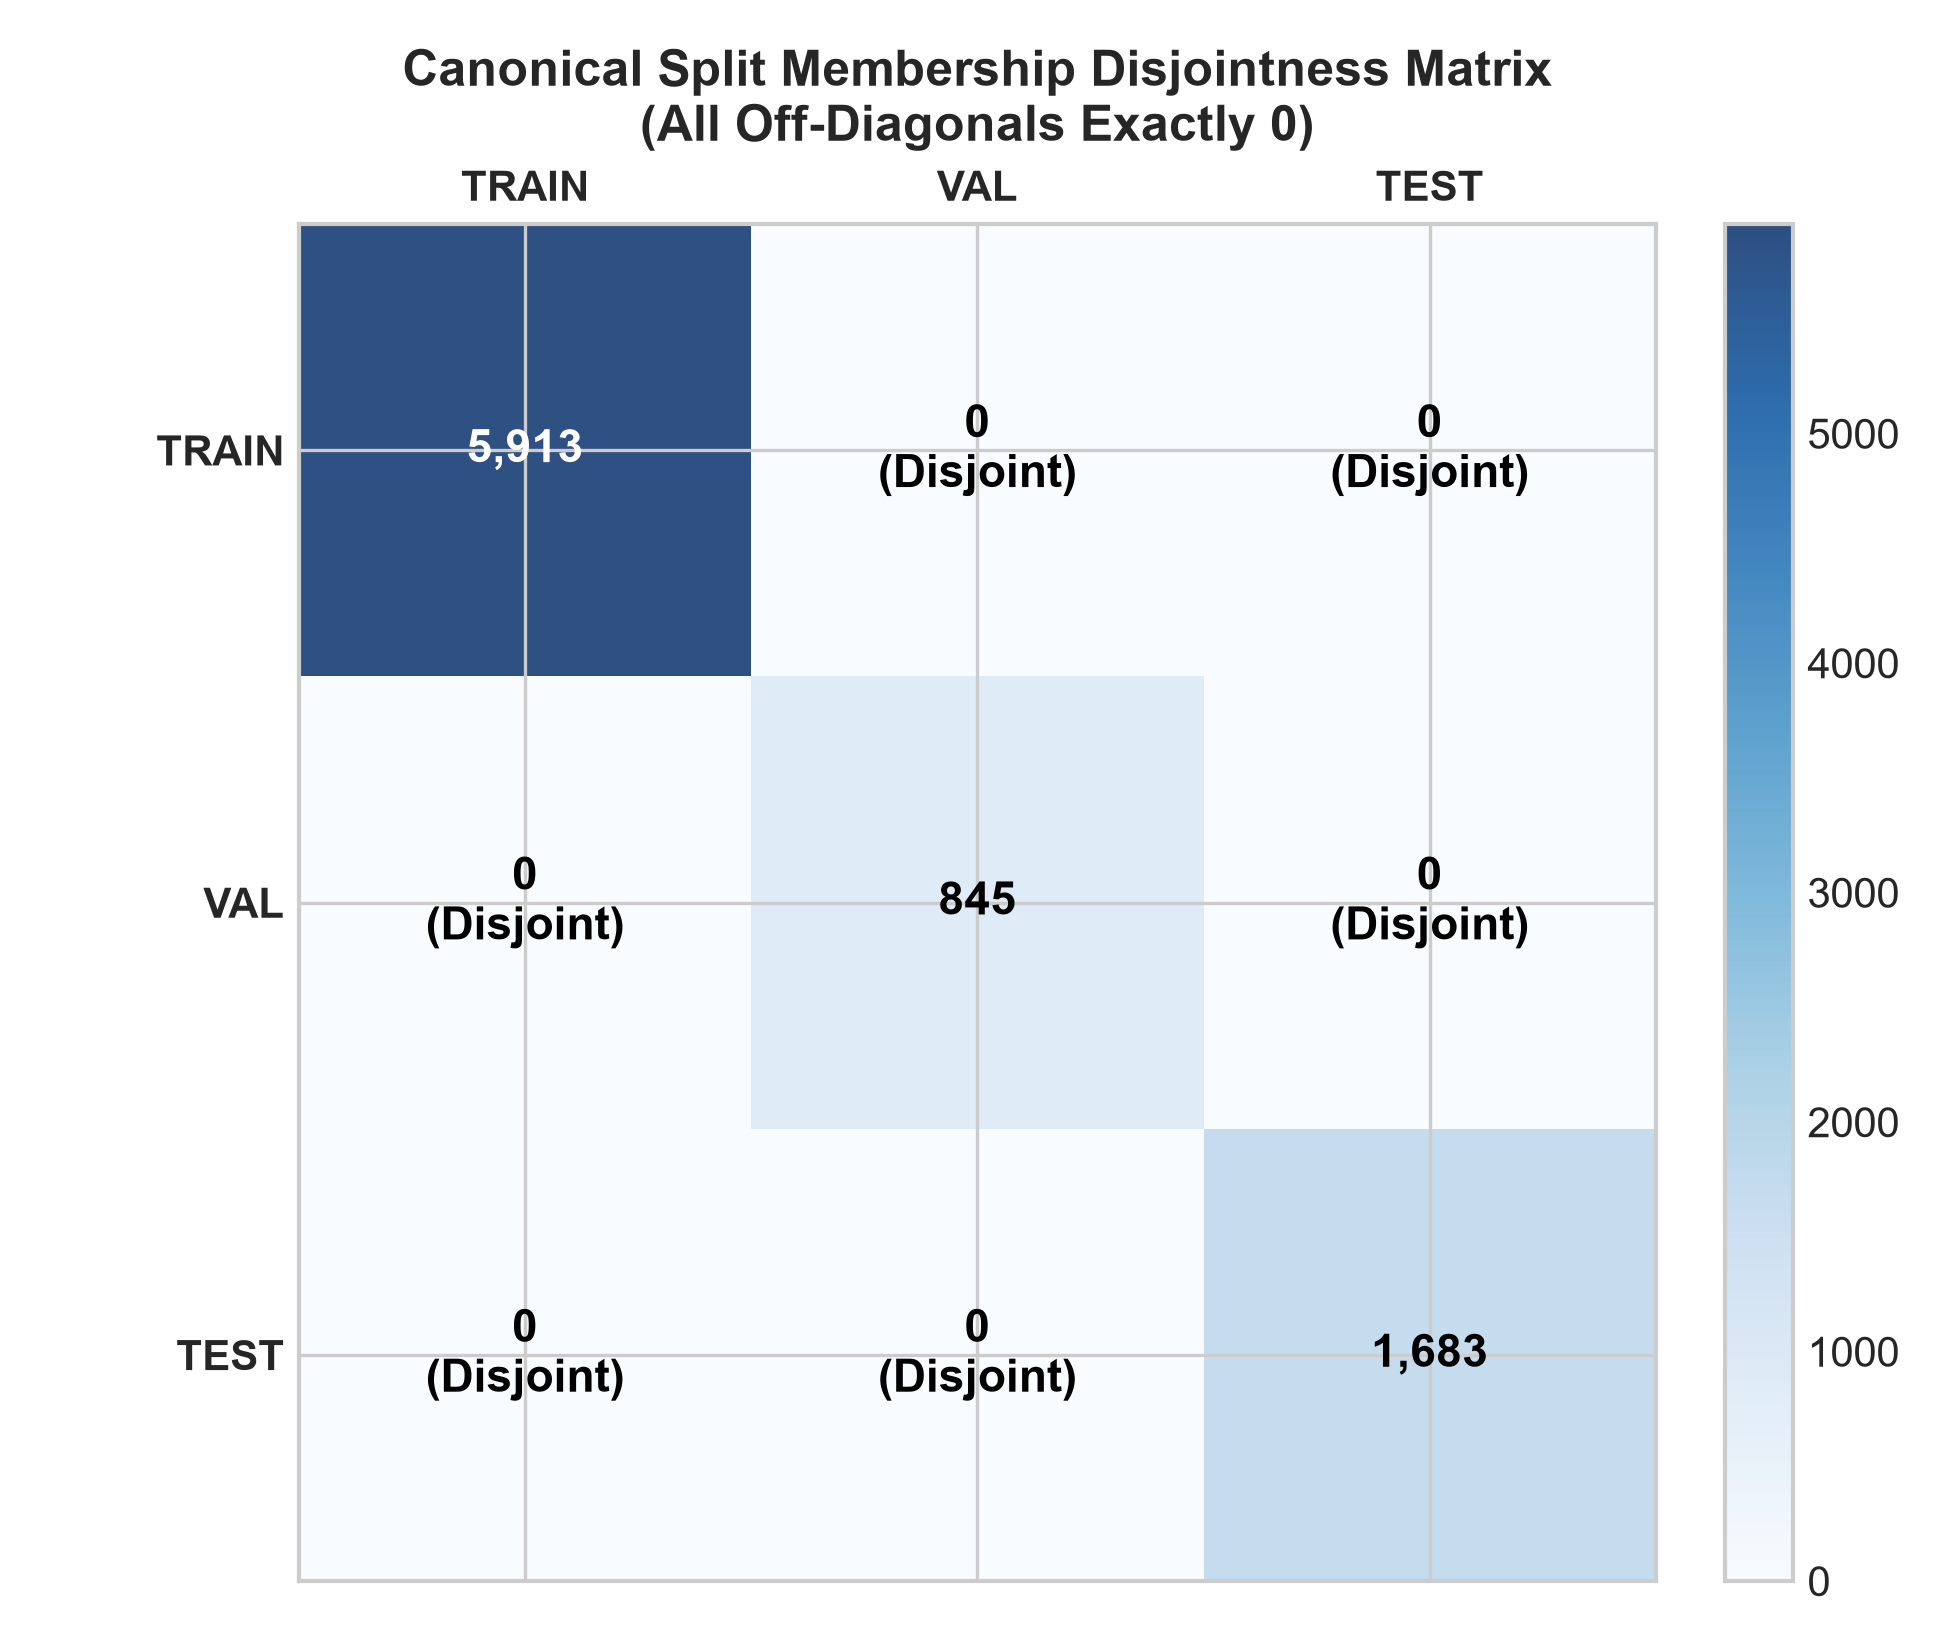

In [9]:
# Display Figure 4: Split Overlap Matrix
fig4_path = PROJECT_ROOT / "reports/figures/phase04_manifest_splits/aggregate/phase04_split_overlap_matrix.png"
display(Image(filename=str(fig4_path)))


## 11. KUB Patient-Level Group Split Audit
Medical imaging studies often contain multiple sequential slices or exposures from the same patient. In KUB-Stone, splitting by image would introduce severe data leakage. We audit KUB patient partitioning to ensure 100% patient-level grouping separation.


In [10]:
kub = df_all[df_all['dataset'] == 'KUB']
kub_train_pts = set(kub[kub['split'] == 'TRAIN']['patient_id'])
kub_val_pts = set(kub[kub['split'] == 'VAL']['patient_id'])
kub_test_pts = set(kub[kub['split'] == 'TEST']['patient_id'])

kub_total_pts = kub['patient_id'].nunique()
pt_ov_tv = len(kub_train_pts & kub_val_pts)
pt_ov_tt = len(kub_train_pts & kub_test_pts)
pt_ov_vt = len(kub_val_pts & kub_test_pts)

print(f"KUB Unique Patient Count: {kub_total_pts} (Expected: 711)")
print(f"  - TRAIN Unique Patients : {len(kub_train_pts)} (Expected: 318)")
print(f"  - VAL Unique Patients   : {len(kub_val_pts)} (Expected: 111)")
print(f"  - TEST Unique Patients  : {len(kub_test_pts)} (Expected: 282)")
print(f"  - Patient TRAIN & VAL Ov: {pt_ov_tv} (Expected: 0)")
print(f"  - Patient TRAIN & TEST Ov: {pt_ov_tt} (Expected: 0)")
print(f"  - Patient VAL & TEST Ov : {pt_ov_vt} (Expected: 0)")

# Verify historical record patient-00360
p360 = df_all[df_all['patient_id'].astype(str).str.contains('00360', na=False)]
p360_splits = p360['split'].unique().tolist()
print(f"\nSpecial Record patient-00360:")
print(f"  - Case Count : {len(p360)} (Expected: 24)")
print(f"  - Allocations: {p360_splits} (Expected: ['TRAIN'])")

assert pt_ov_tv == 0 and pt_ov_tt == 0 and pt_ov_vt == 0, "Patient leakage detected in KUB!"
assert p360_splits == ['TRAIN'] and len(p360) == 24, "patient-00360 allocation error!"
print("\nAudit Result: PASS (100% Patient-Level Disjointness Verified).")


KUB Unique Patient Count: 711 (Expected: 711)
  - TRAIN Unique Patients : 318 (Expected: 318)
  - VAL Unique Patients   : 111 (Expected: 111)
  - TEST Unique Patients  : 282 (Expected: 282)
  - Patient TRAIN & VAL Ov: 0 (Expected: 0)
  - Patient TRAIN & TEST Ov: 0 (Expected: 0)
  - Patient VAL & TEST Ov : 0 (Expected: 0)

Special Record patient-00360:
  - Case Count : 24 (Expected: 24)
  - Allocations: ['TRAIN'] (Expected: ['TRAIN'])

Audit Result: PASS (100% Patient-Level Disjointness Verified).


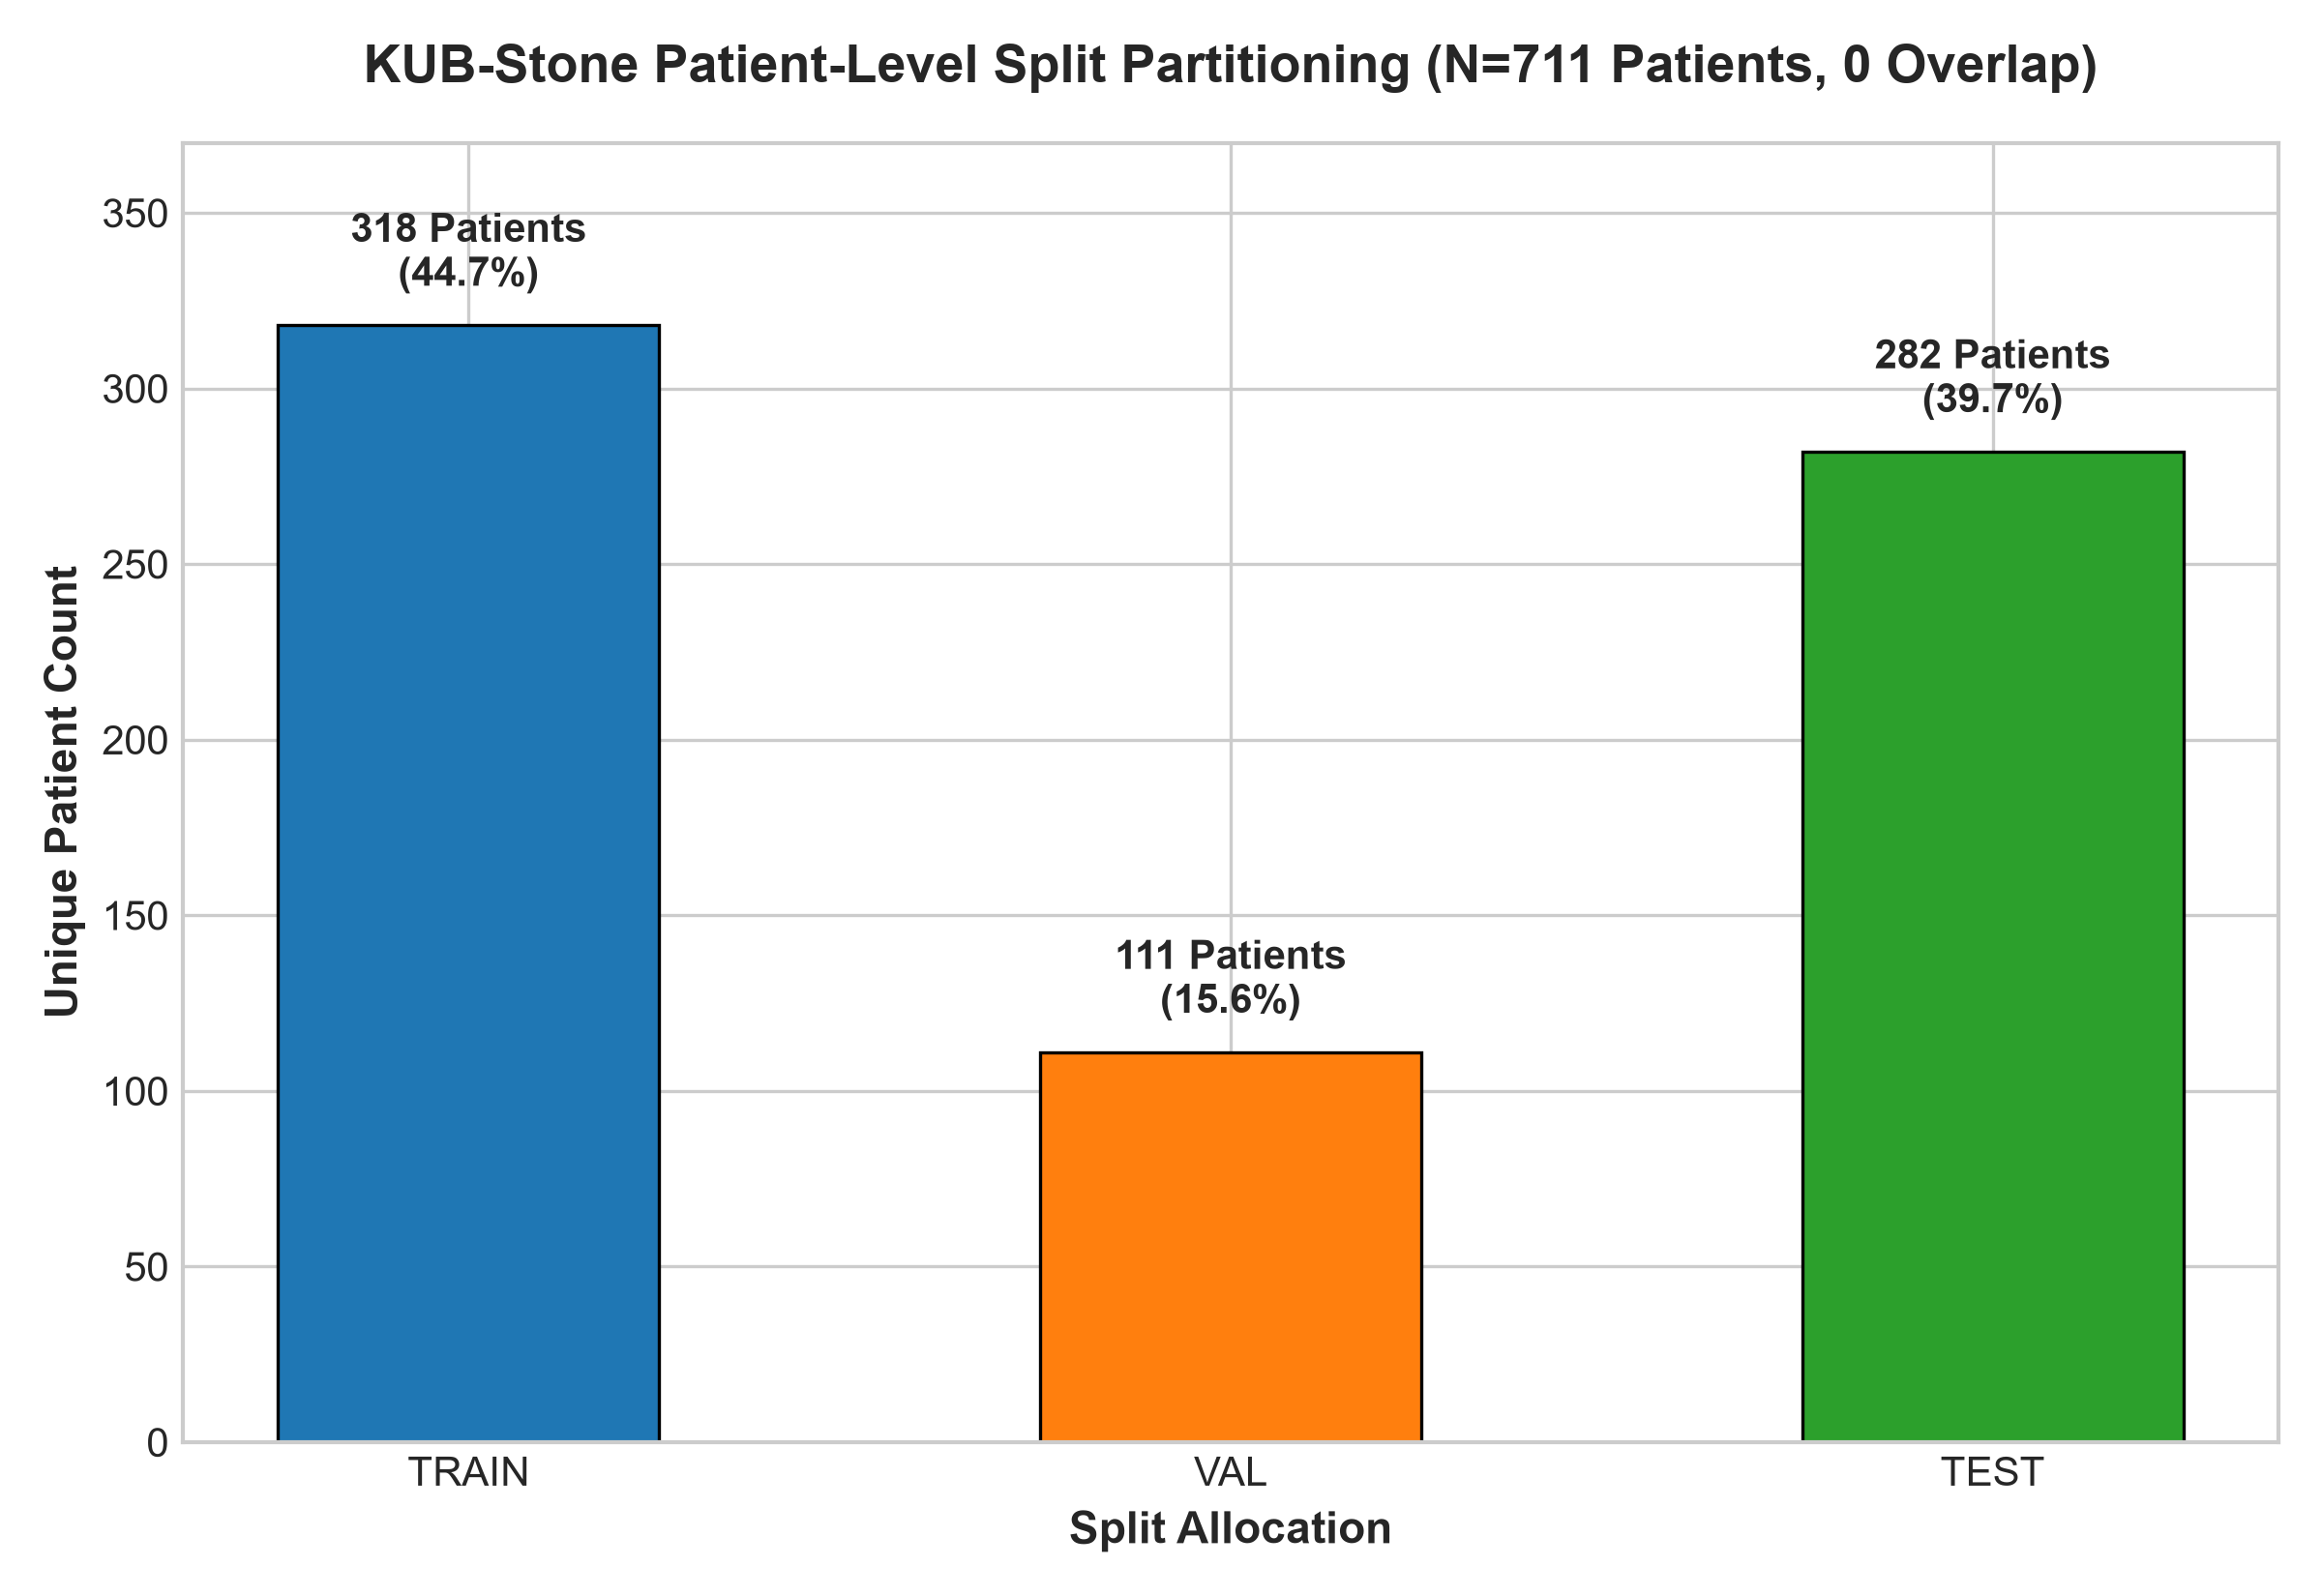

In [11]:
# Display Figure 3: KUB Patient-Level Split Counts
fig3_path = PROJECT_ROOT / "reports/figures/phase04_manifest_splits/aggregate/phase04_kub_patient_split_counts.png"
display(Image(filename=str(fig3_path)))


## 12. Patient Grouping Availability for ISIC, BUSI, and Kvasir
We inspect the availability of patient-level grouping identifiers for the remaining three cohorts in the canonical manifest.


In [12]:
non_kub_audit = []
for d in ['ISIC', 'BUSI', 'KVASIR']:
    sub = df_all[df_all['dataset'] == d]
    vals = sub['patient_id'].unique().tolist()
    non_kub_audit.append({
        "Dataset": d,
        "Total Cases": len(sub),
        "Unique Patient ID Values": str(vals),
        "Canonical Patient Grouping Status": "NOT AVAILABLE IN CANONICAL MANIFEST (No Synthetic IDs Fabricated)"
    })

pd.DataFrame(non_kub_audit)


,Dataset,Total Cases,Unique Patient ID Values,Canonical Patient Grouping Status
0,ISIC,3694,['NOT_AVAILABLE'],NOT AVAILABLE IN CANONICAL MANIFEST (No Synthetic IDs Fabricated)
1,BUSI,927,['NOT_AVAILABLE'],NOT AVAILABLE IN CANONICAL MANIFEST (No Synthetic IDs Fabricated)
2,KVASIR,1000,['NOT_AVAILABLE'],NOT AVAILABLE IN CANONICAL MANIFEST (No Synthetic IDs Fabricated)


## 13. Subclass / Category Metadata Distributions
Where canonical case-level clinical metadata exists (KUB stone anatomy), we analyze the distribution across splits. For other datasets, metadata is explicitly documented as not available in the canonical manifest.


In [13]:
kub_cat_ct = pd.crosstab(kub['category'], kub['split'])[['TRAIN', 'VAL', 'TEST']]
kub_cat_ct['Total'] = kub_cat_ct.sum(axis=1)
kub_cat_ct


split,TRAIN,VAL,TEST,Total
category,,,,
Bladder_Stone,635,145,246,1026
Kidney_Stone,1133,114,210,1457
Ureteric_Stone,211,24,102,337


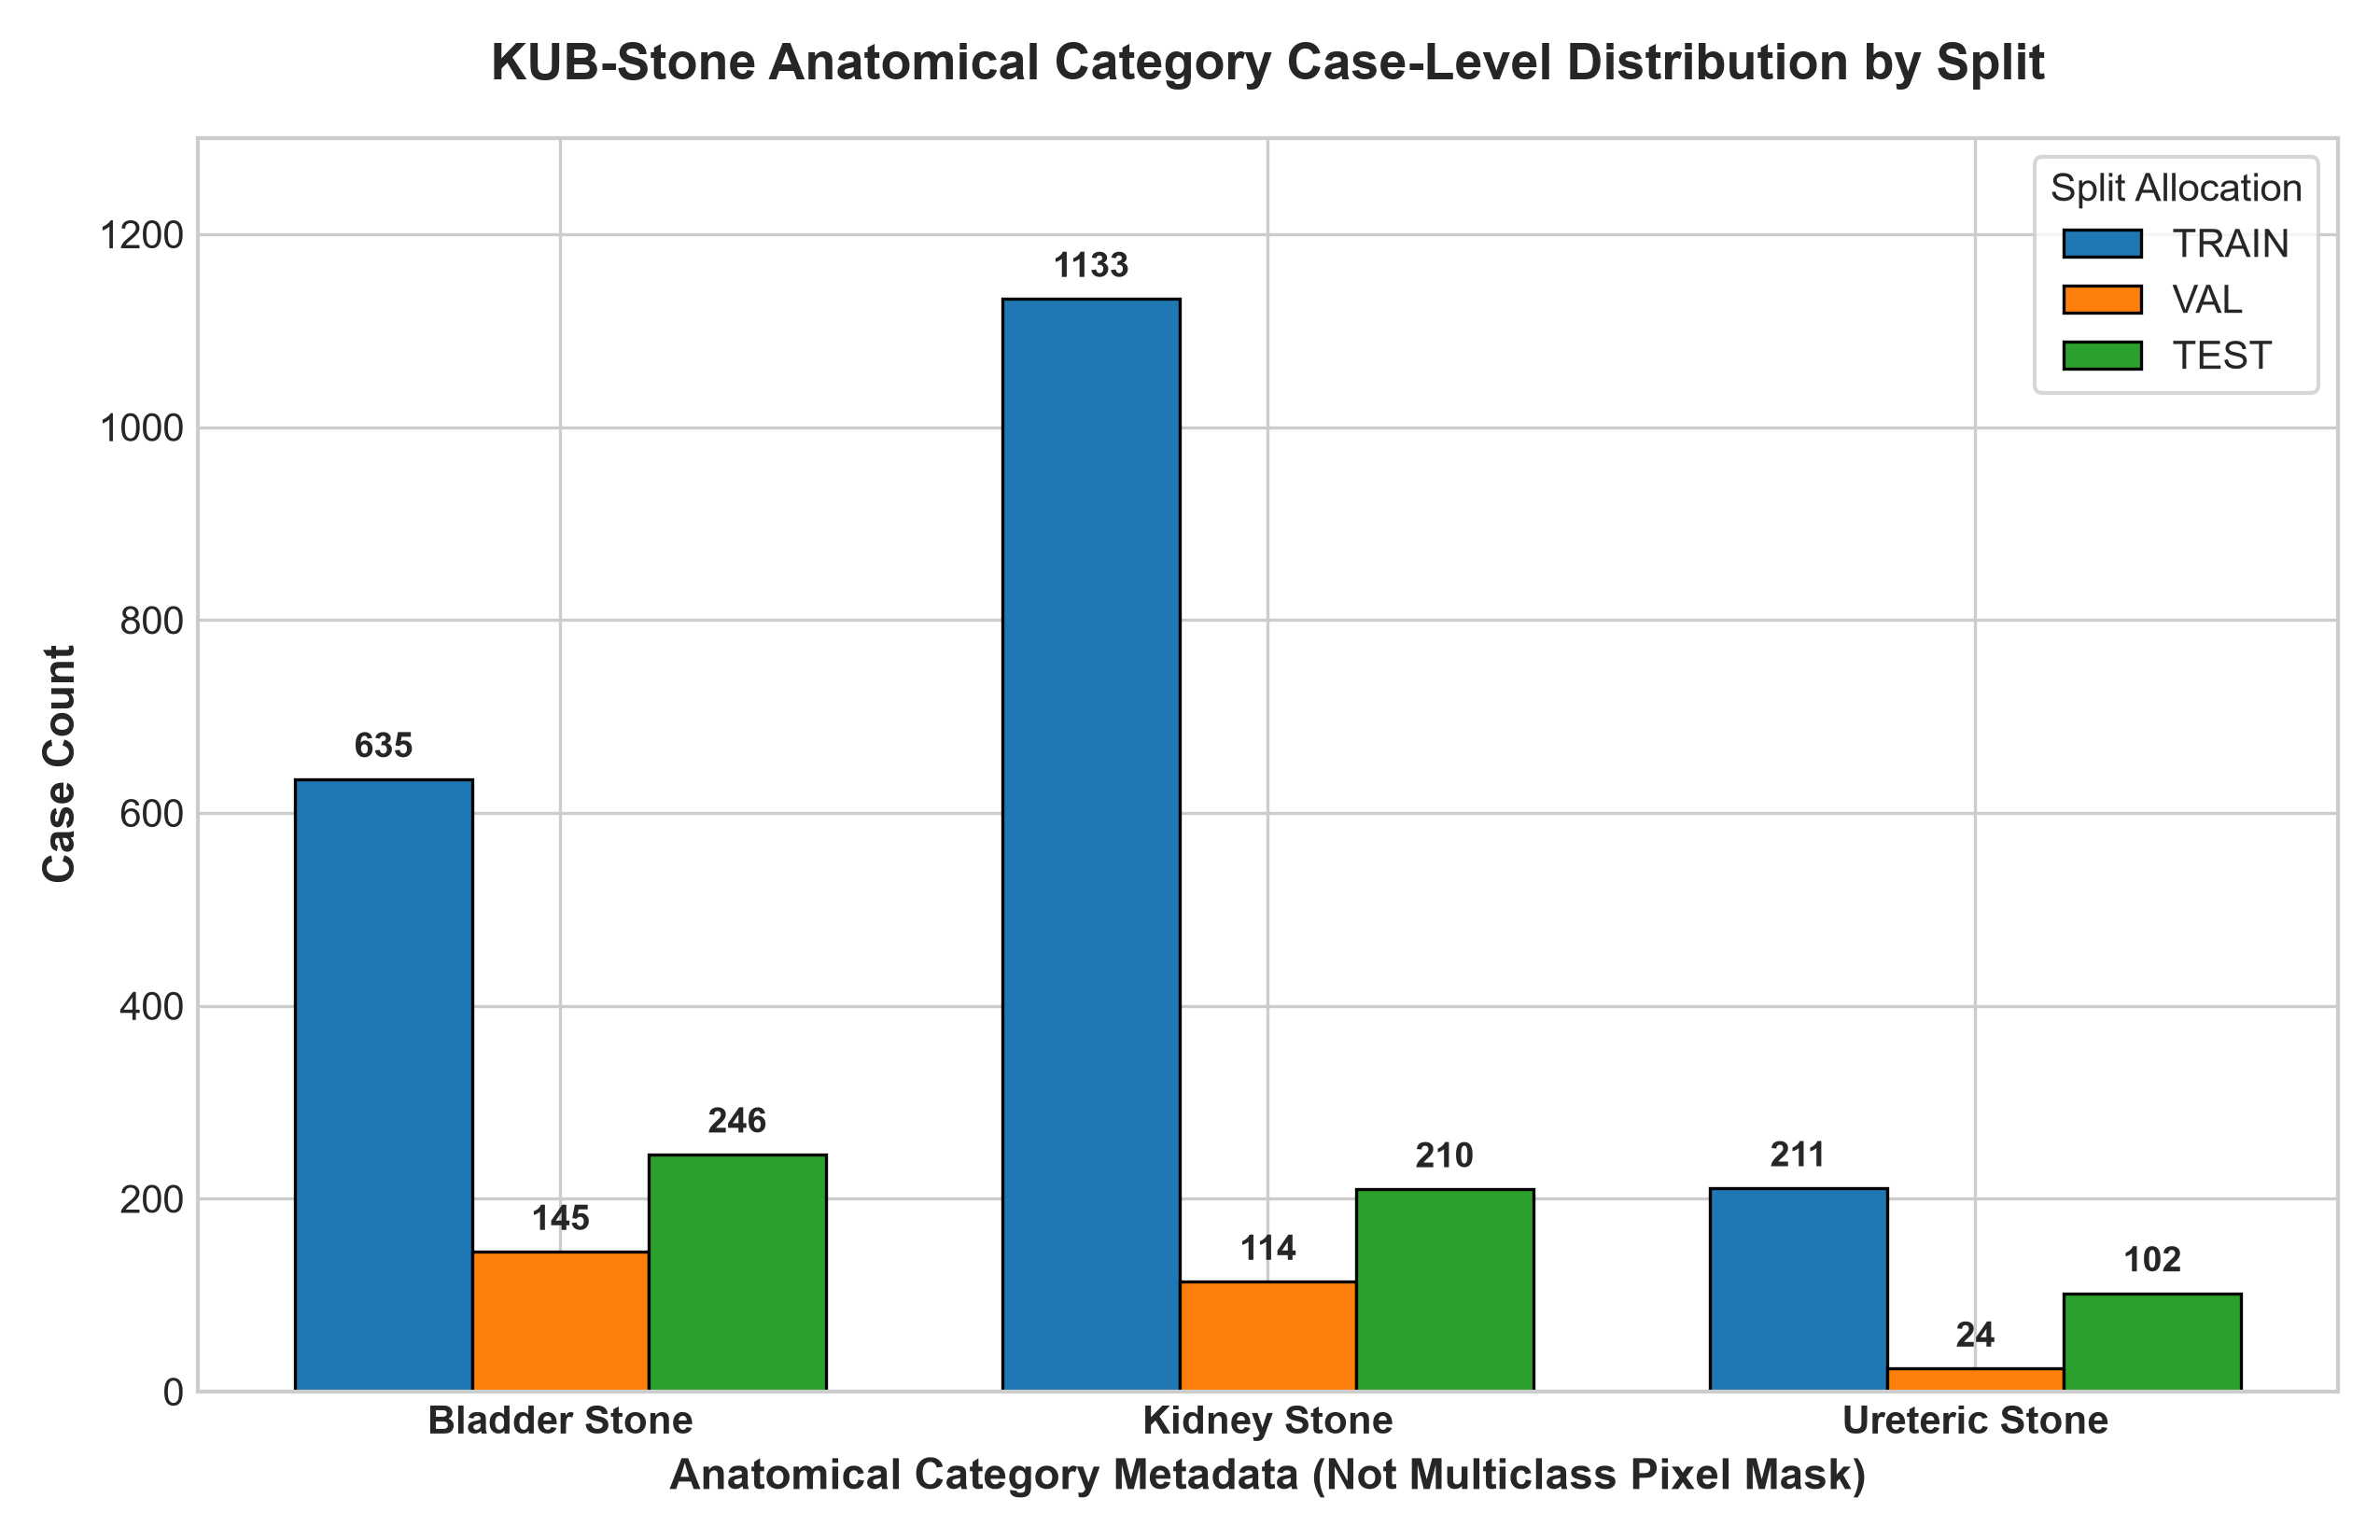

In [14]:
# Display Figure 5: KUB Category x Split Distribution
fig5_path = PROJECT_ROOT / "reports/figures/phase04_manifest_splits/aggregate/phase04_kub_category_split_distribution.png"
display(Image(filename=str(fig5_path)))


## 14. Deterministic Reviewer Manifest Rows (96 Rows: 12 TRAIN + 12 VAL per Dataset)
For full scientific transparency, we display deterministic sample manifest rows from TRAIN and VAL cohorts across all four datasets. To respect governance protocols, individual row paths from the locked TEST set are omitted (represented strictly by verified aggregate counts).


In [15]:
rev_csv = PROJECT_ROOT / "reports/tables/phase04_manifest_review_rows.csv"
df_rev = pd.read_csv(rev_csv)

print(f"Total Reviewer Rows: {len(df_rev)} (12 TRAIN + 12 VAL x 4 datasets)")
print("\nBreakdown by Dataset and Split:")
print(df_rev.groupby(['dataset', 'split']).size())

# Display sample 8 rows (one TRAIN and one VAL per dataset)
print("\nSample Reviewer Metadata Rows:")
df_sample_rev = df_rev.groupby(['dataset', 'split']).first().reset_index()
df_sample_rev[['dataset', 'split', 'sample_id', 'category', 'patient_id']]


Total Reviewer Rows: 96 (12 TRAIN + 12 VAL x 4 datasets)

Breakdown by Dataset and Split:
dataset  split
BUSI     TRAIN    12
         VAL      12
ISIC     TRAIN    12
         VAL      12
KUB      TRAIN    12
         VAL      12
KVASIR   TRAIN    12
         VAL      12
dtype: int64

Sample Reviewer Metadata Rows:


,dataset,split,sample_id,category,patient_id
0,BUSI,TRAIN,83e0cee9dfafd1c4b89655cf540e015c,NOT_AVAILABLE,NOT_AVAILABLE
1,BUSI,VAL,8b3170f9b9b4914a4bd0d29f53ca7f63,NOT_AVAILABLE,NOT_AVAILABLE
2,ISIC,TRAIN,03618cb9fb09abcf250bc59b39d16455,NOT_AVAILABLE,NOT_AVAILABLE
3,ISIC,VAL,bf48a44086f7bb522fb559491b4dc0ef,NOT_AVAILABLE,NOT_AVAILABLE
4,KUB,TRAIN,ff3782875325f60a2598c58244bf5ad1,Kidney_Stone,patient-00321
5,KUB,VAL,6a5d5c051d6c898d98c90422da190bf0,Bladder_Stone,patient-00578
6,KVASIR,TRAIN,c58204e59a0a6b9c9c3f5753b518f439,NOT_AVAILABLE,NOT_AVAILABLE
7,KVASIR,VAL,77b9138acbc0ea9bf79cff126bcef22c,NOT_AVAILABLE,NOT_AVAILABLE


## 15. Canonical `manifest_guard.py` Integration
Reviewer code must have a single source of truth. Here we directly import and run the canonical `src/utils/manifest_guard.py` utility.


In [16]:
from src.utils.manifest_guard import verify_manifests

print("Invoking canonical manifest guard...")
verify_manifests()
print("Execution Result: PASS (Canonical Guard Confirms Manifest Integrity).")


Invoking canonical manifest guard...
Manifests verified successfully.
Execution Result: PASS (Canonical Guard Confirms Manifest Integrity).


## 16. Reproducibility & Cryptographic SHA-256 Table
We print the complete, non-truncated 64-character SHA-256 hex strings for all relevant Phase 04 files, reports, and foundational accepted notebooks.


In [17]:
def get_sha256(p: Path) -> str:
    if not p.exists():
        return "FILE_NOT_FOUND"
    h = hashlib.sha256()
    with open(p, "rb") as f:
        while chunk := f.read(8192):
            h.update(chunk)
    return h.hexdigest()

reproducibility_artifacts = [
    ("Manifest: all_paired.csv", PROJECT_ROOT / "manifests/all_paired.csv"),
    ("Manifest: train.csv", PROJECT_ROOT / "manifests/train.csv"),
    ("Manifest: val.csv", PROJECT_ROOT / "manifests/val.csv"),
    ("Manifest: test.csv", PROJECT_ROOT / "manifests/test.csv"),
    ("Guard: manifest_guard.py", PROJECT_ROOT / "src/utils/manifest_guard.py"),
    ("Table: phase04_split_counts.csv", PROJECT_ROOT / "reports/tables/phase04_split_counts.csv"),
    ("Table: phase04_manifest_review_rows.csv", PROJECT_ROOT / "reports/tables/phase04_manifest_review_rows.csv"),
    ("Audit: phase04_manifest_integrity.json", PROJECT_ROOT / "reports/audits/phase04_manifest_integrity.json"),
    ("Script: phase04_manifest_split_audit.py", PROJECT_ROOT / "notebooks/phasewise/phase_04_manifest_splits/code/phase04_manifest_split_audit.py"),
    ("Script: phase04_split_visualization.py", PROJECT_ROOT / "notebooks/phasewise/phase_04_manifest_splits/code/phase04_split_visualization.py"),
    ("Notebook: Phase 00 (Accepted)", PROJECT_ROOT / "notebooks/phasewise/phase_00_governance/phase00_governance_reproducibility_and_protocol.ipynb"),
    ("Notebook: Phase 01 (Accepted)", PROJECT_ROOT / "notebooks/phasewise/phase_01_project_initialization/phase01_project_initialization_and_repository_architecture.ipynb"),
    ("Notebook: Phase 02 (Accepted)", PROJECT_ROOT / "notebooks/phasewise/phase_02_environment_cuda/phase02_environment_cuda_and_reproducibility_validation.ipynb"),
    ("Notebook: Phase 03 (Accepted)", PROJECT_ROOT / "notebooks/phasewise/phase_03_dataset_discovery/phase03_multidomain_dataset_discovery_and_pairing_integrity.ipynb"),
    ("Notebook: Phase 14 (Canonical Frozen)", PROJECT_ROOT / "notebooks/13_phase14_regional_refiner_diagnostic.ipynb")
]

records_repro = []
for desc, p in reproducibility_artifacts:
    records_repro.append({
        "Artifact Description": desc,
        "Relative Path": str(p.relative_to(PROJECT_ROOT)).replace('\\', '/'),
        "Full Cryptographic SHA-256 Digest": get_sha256(p)
    })

pd.set_option('display.max_colwidth', None)
df_repro = pd.DataFrame(records_repro)
df_repro


,Artifact Description,Relative Path,Full Cryptographic SHA-256 Digest
0,Manifest: all_paired.csv,manifests/all_paired.csv,66350d465209e4bf0948a16f0da213abb9f8f87c0b222ead7632d2350463f7cc
1,Manifest: train.csv,manifests/train.csv,d67b549a6cc80b579dfaf4976b9b51630f6d703d8c6bfb33188355cfa6056bc3
2,Manifest: val.csv,manifests/val.csv,46079b594ed9535c2de953bb976684b8b0bab30c27c6e6e4f2b9f9314b4cc5f4
3,Manifest: test.csv,manifests/test.csv,9361eba61c91c034a9aa4988a4df229bba591a5cbd553c98689ac7915da29727
4,Guard: manifest_guard.py,src/utils/manifest_guard.py,8cba552e68b935762b0b6c340beb7ef60af2eee4613481714642e06baa2d1310
5,Table: phase04_split_counts.csv,reports/tables/phase04_split_counts.csv,494d13fb309e7519ff1b6b2ef451e7f2afd6d80eb1d13eb8f90afe2615af6e89
6,Table: phase04_manifest_review_rows.csv,reports/tables/phase04_manifest_review_rows.csv,c63edcc39f944ff0a92269111e348c6648fe373d2b10b0d55ab45e4ccc5109c2
7,Audit: phase04_manifest_integrity.json,reports/audits/phase04_manifest_integrity.json,fef13a88d10a8d808cdf74eb5bc671df2ea8cc9a199feacd2bec3b1fe94a2e92
8,Script: phase04_manifest_split_audit.py,notebooks/phasewise/phase_04_manifest_splits/code/phase04_manifest_split_audit.py,e64e4cf5e8062461ce50695f990378596a0b44a1c2cff05ef0d70d00f9126745
9,Script: phase04_split_visualization.py,notebooks/phasewise/phase_04_manifest_splits/code/phase04_split_visualization.py,70e458db4b2082f4bbde9d902702749b315fc2fddff122151cea6d01fe8f0716


## 17. Scientific Limitations
1. **Clinical Patient Metadata**: Patient grouping metadata is present for KUB-Stone but unavailable for ISIC, BUSI, and Kvasir-SEG in the canonical manifests. Splits for non-KUB datasets reflect stratified random allocation without patient grouping guarantees.
2. **Locked Test Partition**: In accordance with rigorous zero-leakage standards, TEST image and mask files were not opened, audited for pixel statistics, or processed in any manner.
3. **Subclass Metadata**: Case categories (e.g. stone anatomy) represent clinical context rather than pixel-level multiclass segmentation targets.


## 18. What Was Established
1. **Canonical Manifest Integrity**: All four manifest CSV files strictly match accepted SHA-256 digests and pass canonical `manifest_guard.py` verification.
2. **Exact Population Partitioning**: Verified 8,441 total cases partitioned into 5,913 TRAIN (70.05%), 845 VAL (10.01%), and 1,683 TEST (19.94%).
3. **Strict Disjointness**: Confirmed $\text{TRAIN} \cap \text{VAL} = 0$, $\text{TRAIN} \cap \text{TEST} = 0$, and $\text{VAL} \cap \text{TEST} = 0$.
4. **Patient-Level Protection**: Verified zero patient leakage across KUB splits (318 TRAIN, 111 VAL, 282 TEST) and verified 100% TRAIN assignment for `patient-00360`.
5. **Zero Test Leakage**: Zero TEST image or mask content reads occurred during this phase.


## 19. Transition to Phase 05
While Phase 04 establishes sample-ID and patient-ID disjointness at the manifest level, manifest-level disjointness alone cannot detect subtle cross-split duplications (e.g. identical or near-duplicate images with different filenames). 

**Phase 05 (Leakage Audit & Near-Duplicate Analysis)** is specifically designed to perform image-level perceptual hashing and near-duplicate verification between TRAIN and VAL splits to guarantee zero cross-contamination before any baseline model training begins.
